Seaborn version   : 0.13.2
Matplotlib version: 3.10.0


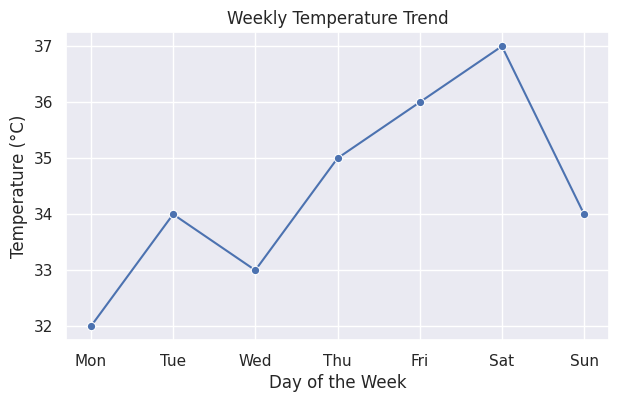

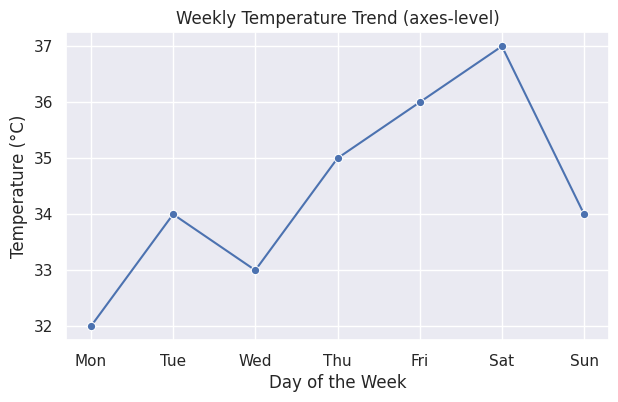

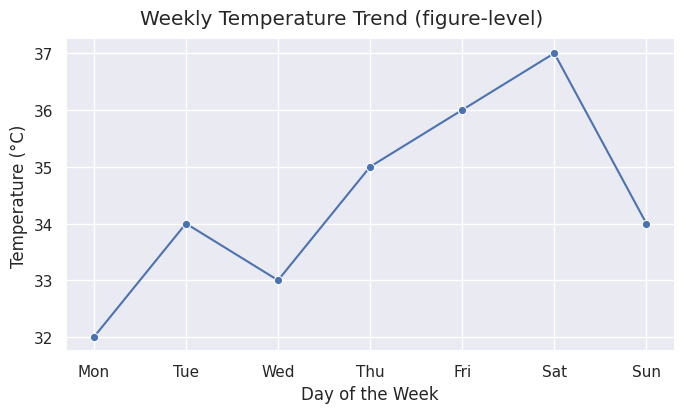

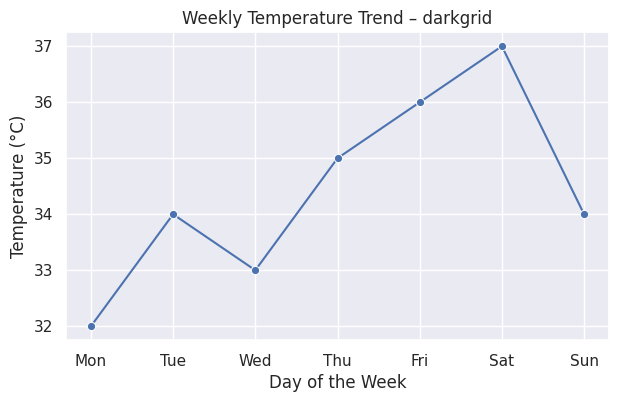

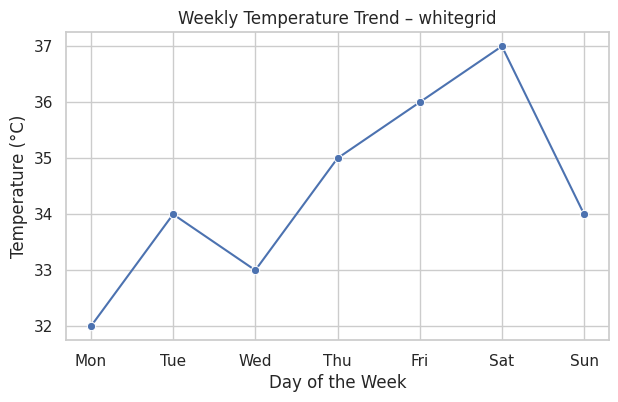

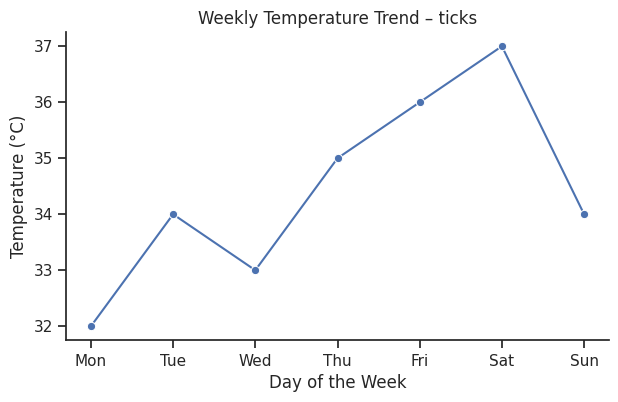

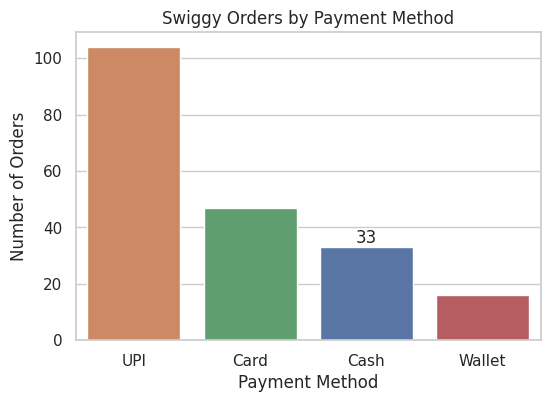

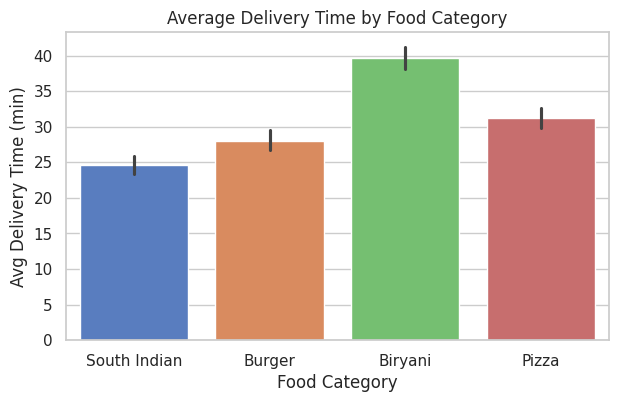

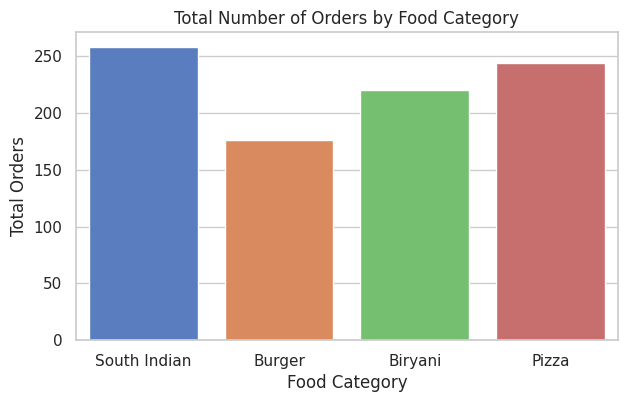

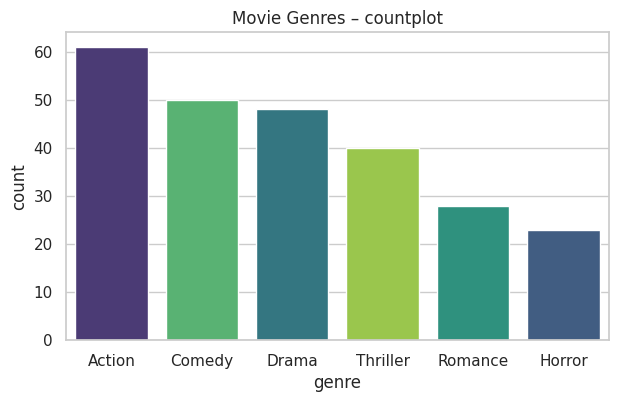

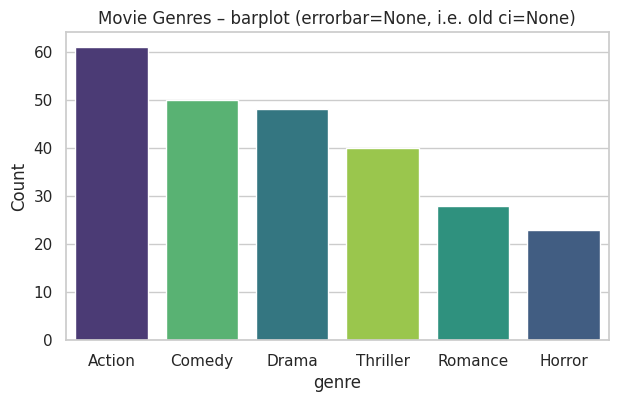

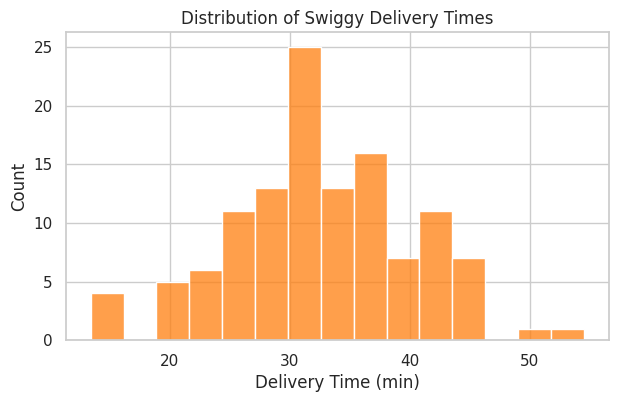

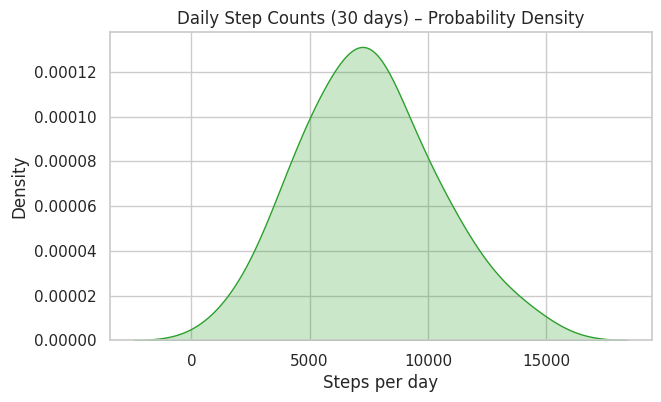

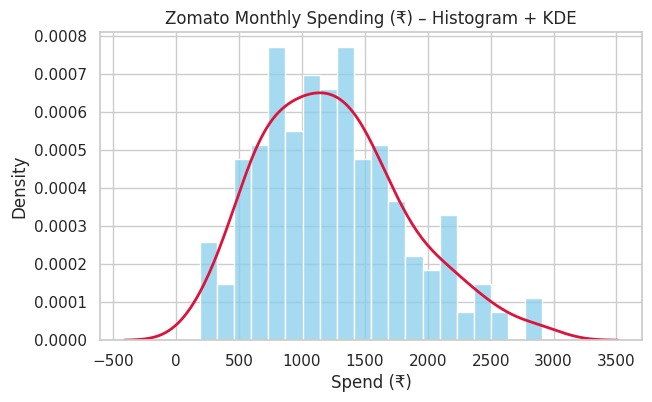

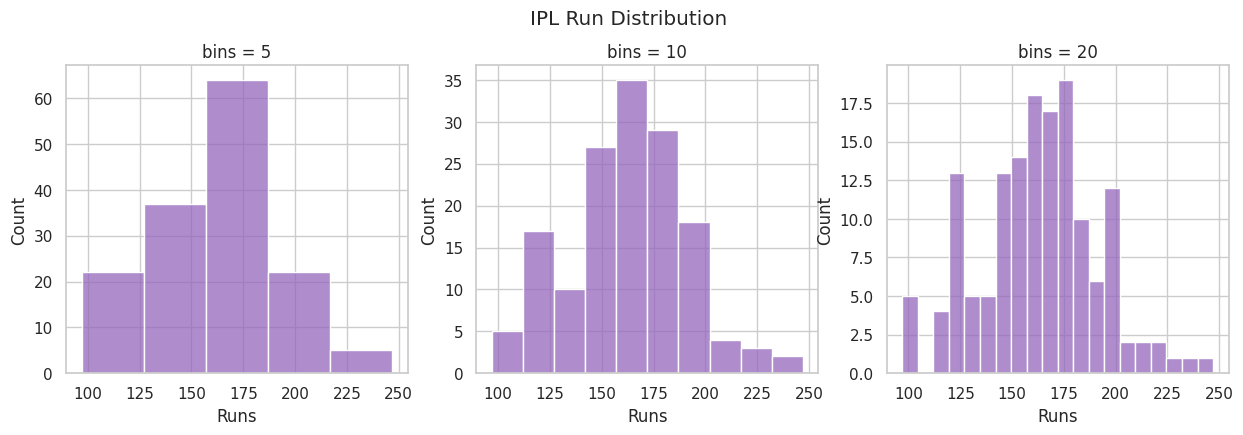

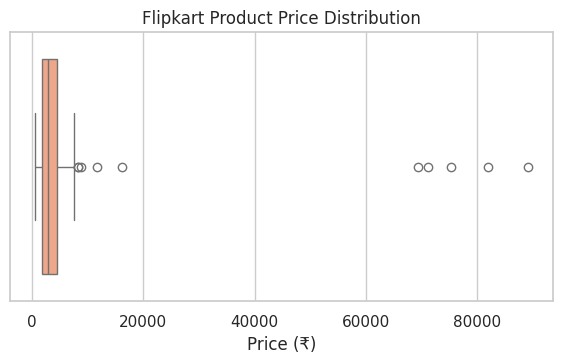

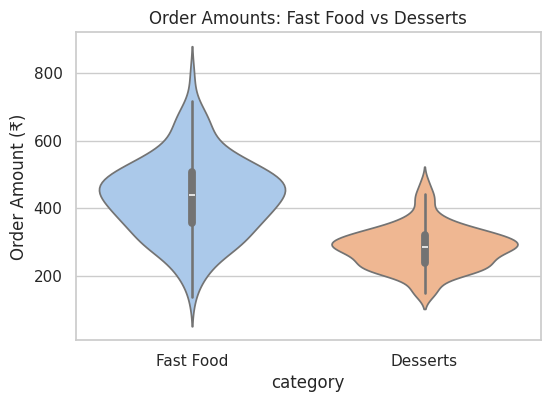

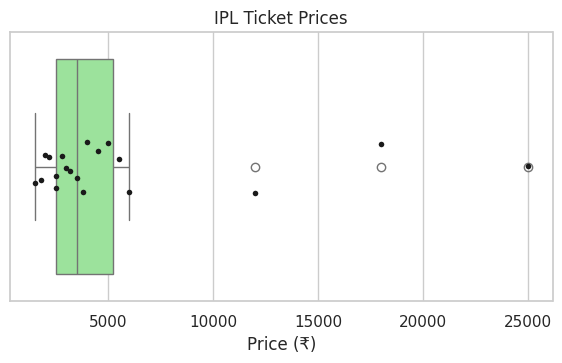

Q1=2500.0, Q3=5250.0, IQR=2750.0, whisker limits=(-1625.0, 9375.0)
Outliers: [12000 18000 25000]


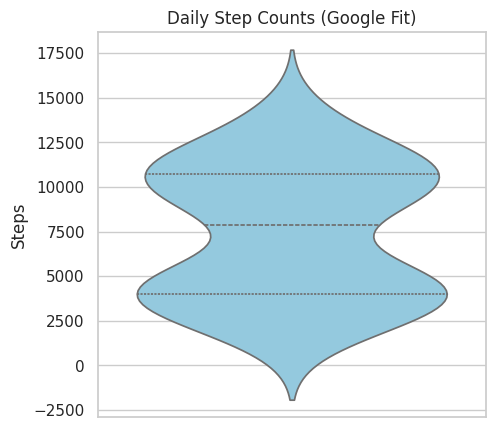

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


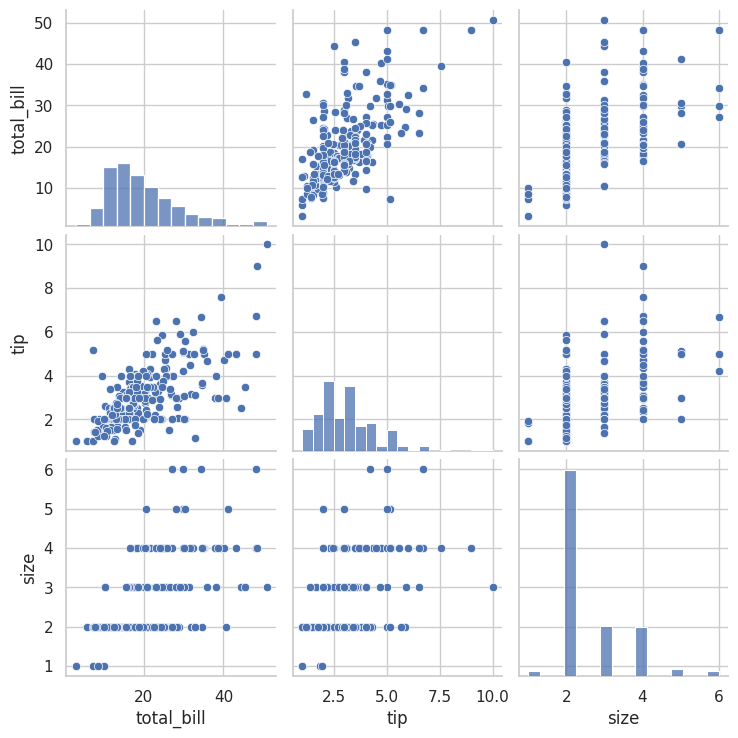

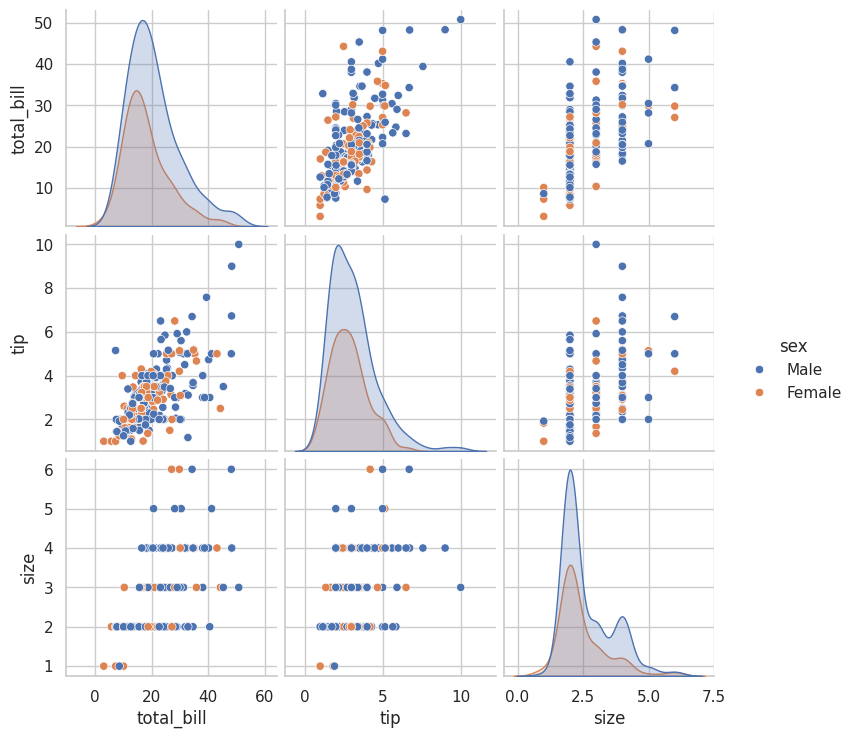

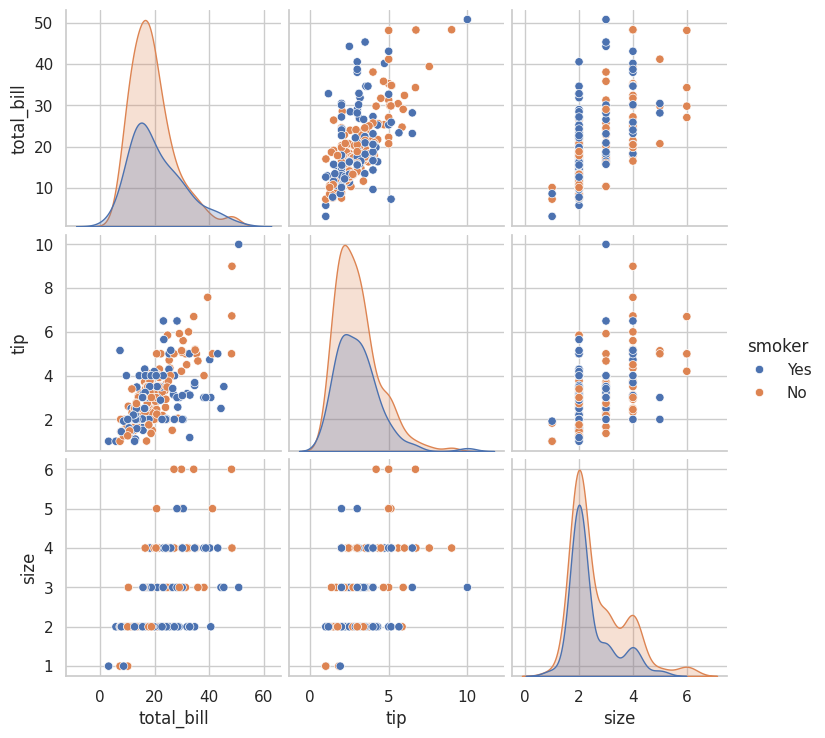

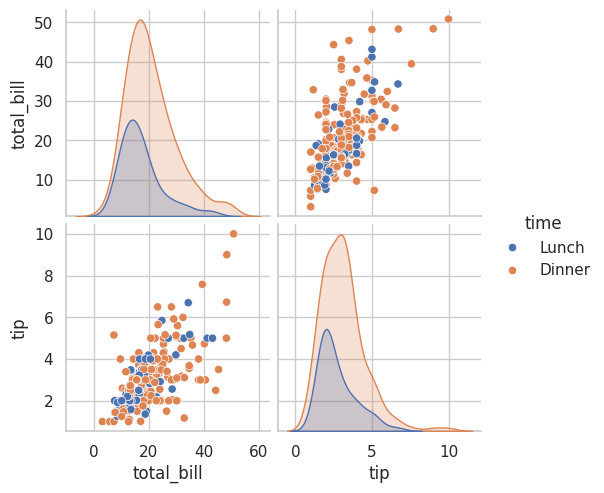

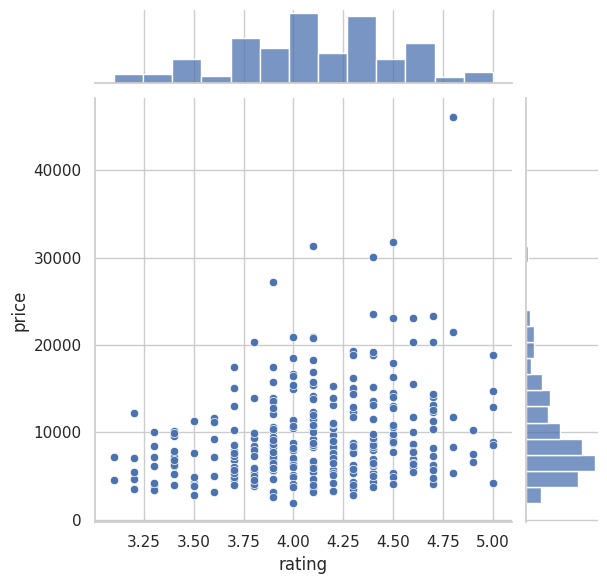

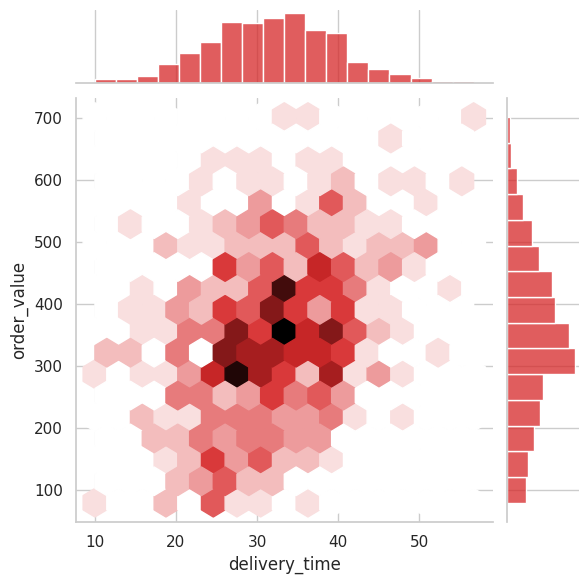

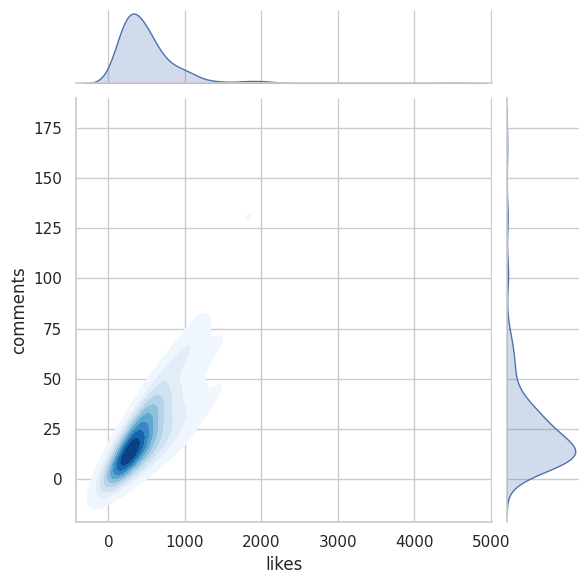

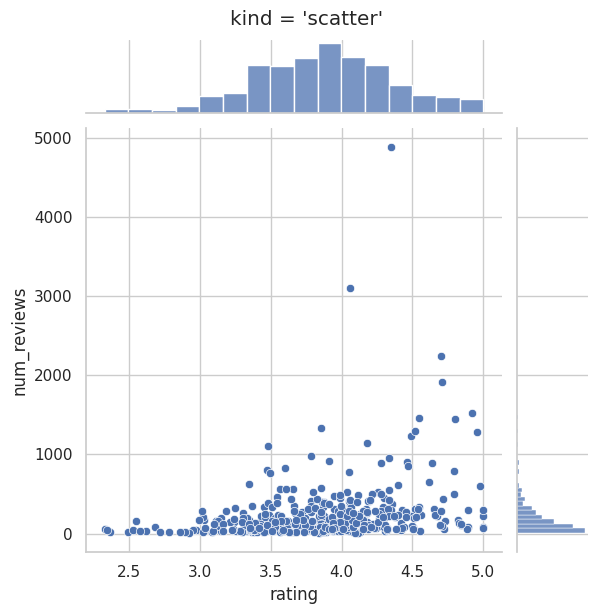

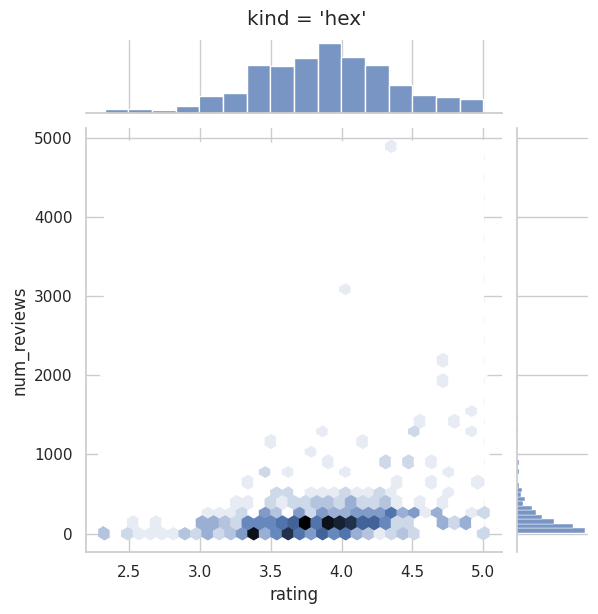

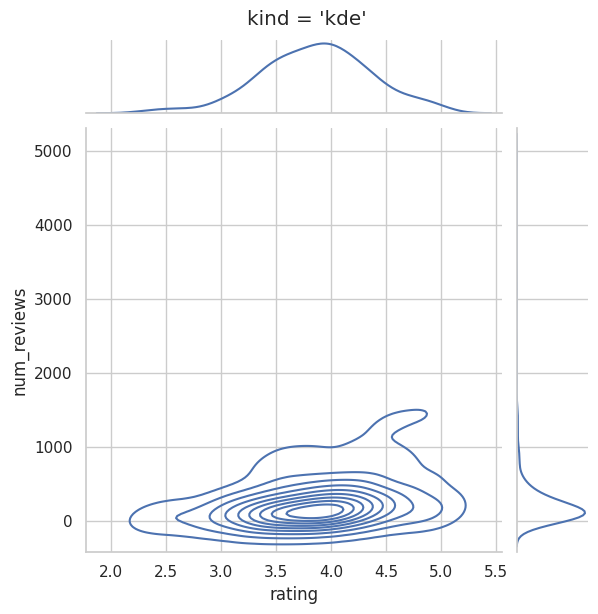

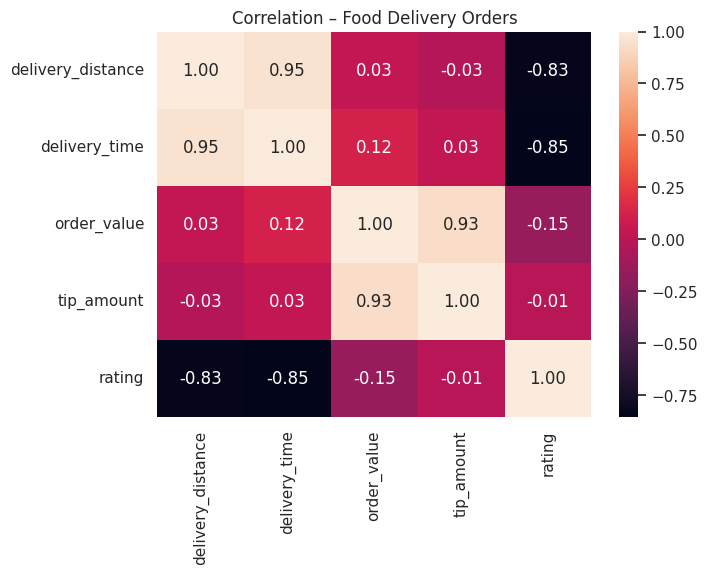

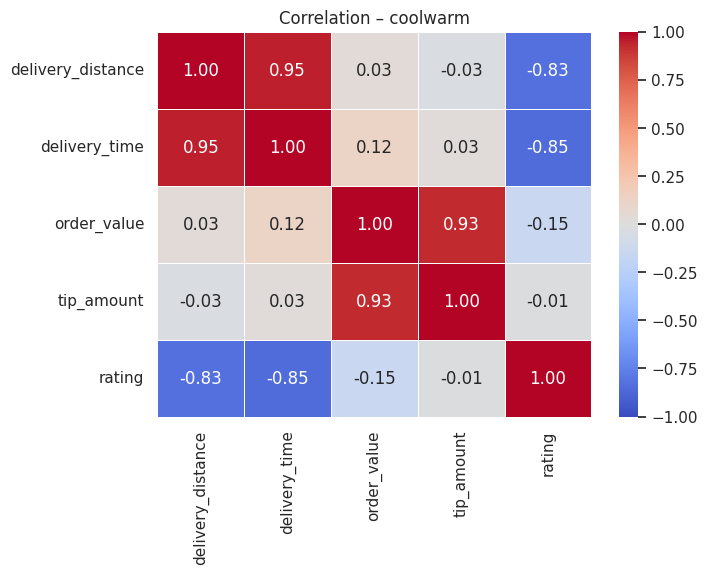

Strongest negative correlation: ('delivery_time', 'rating') = -0.85


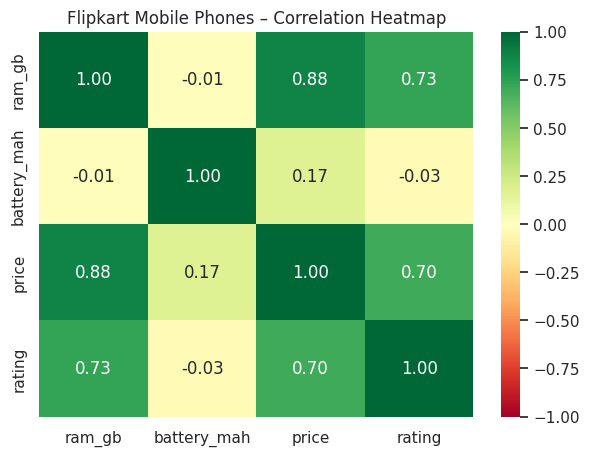

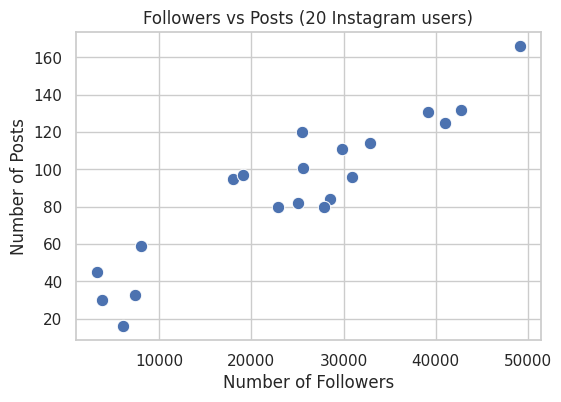

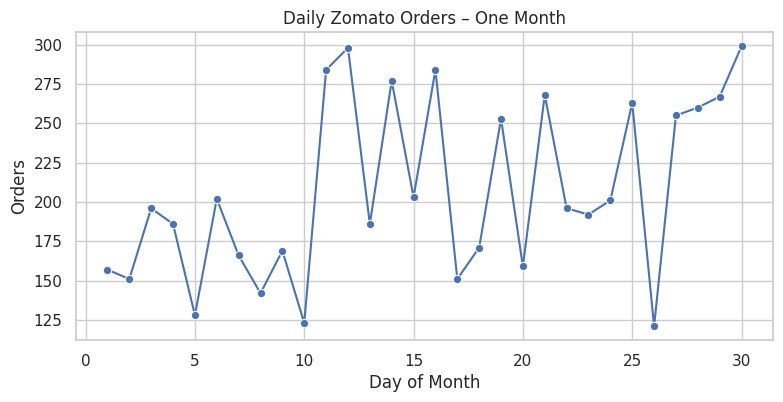

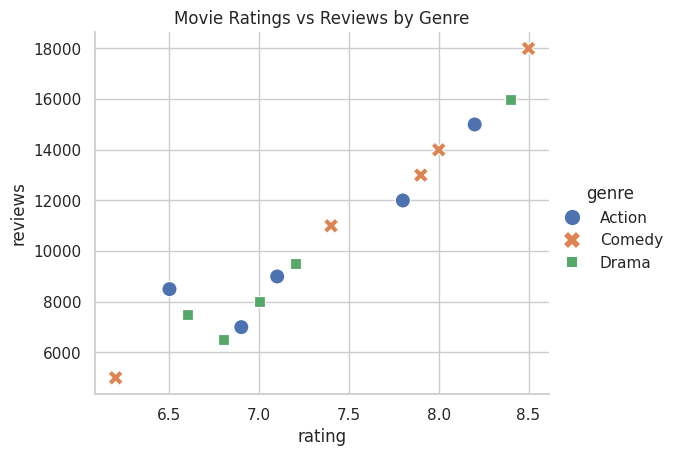

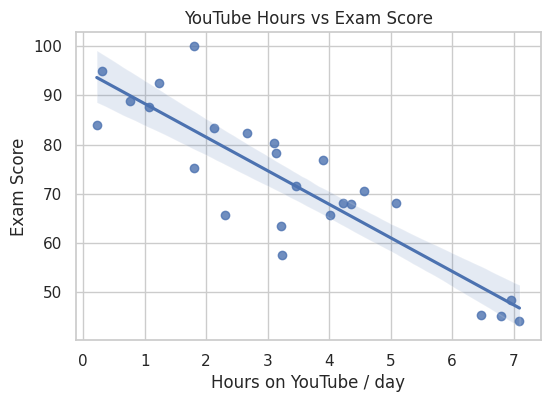

Correlation r = -0.88


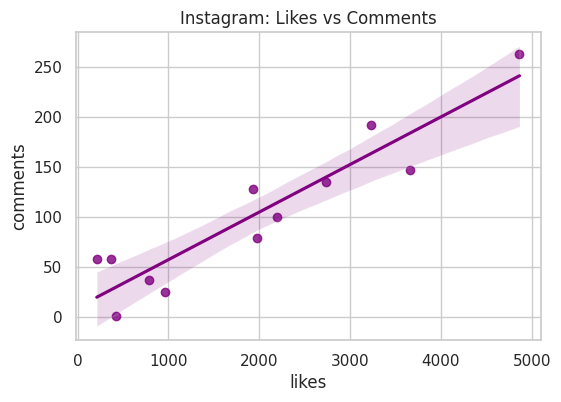

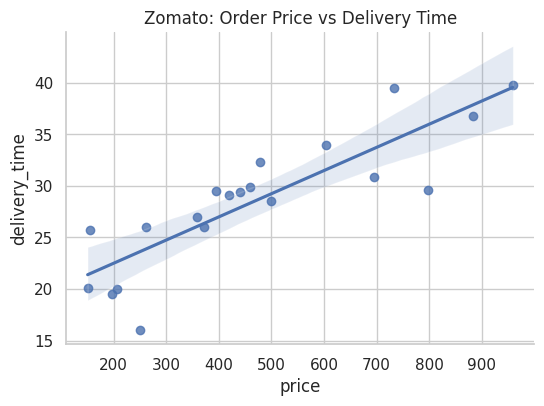

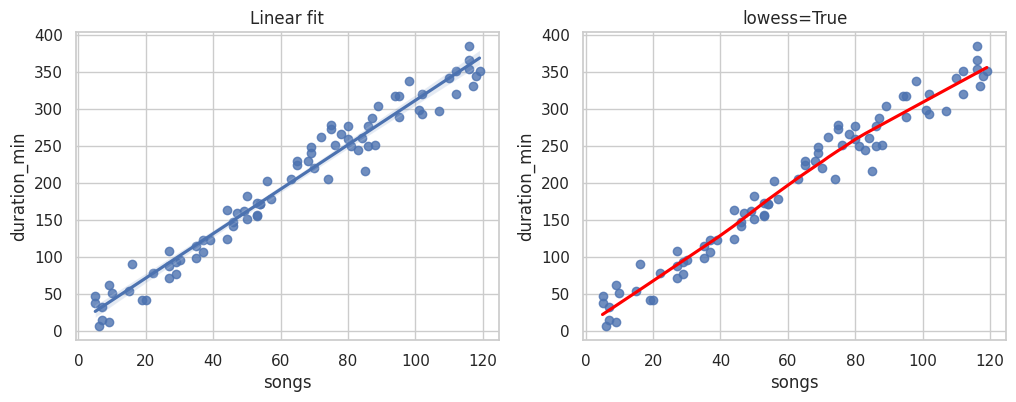

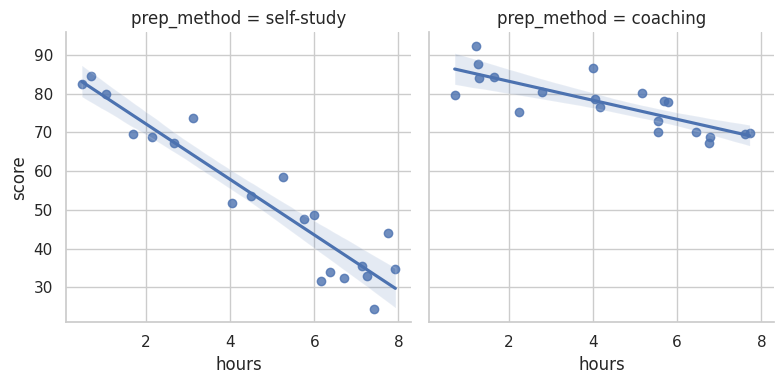

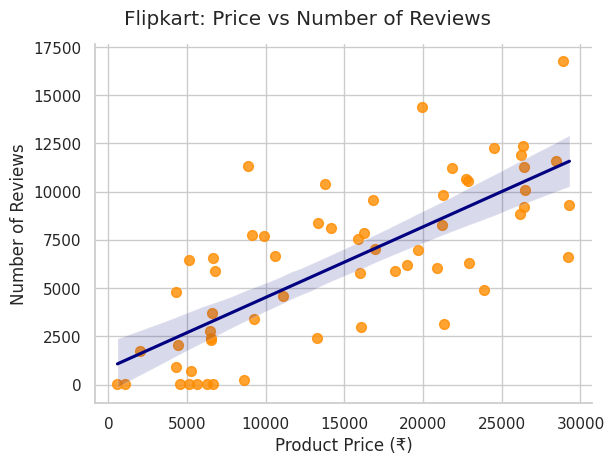

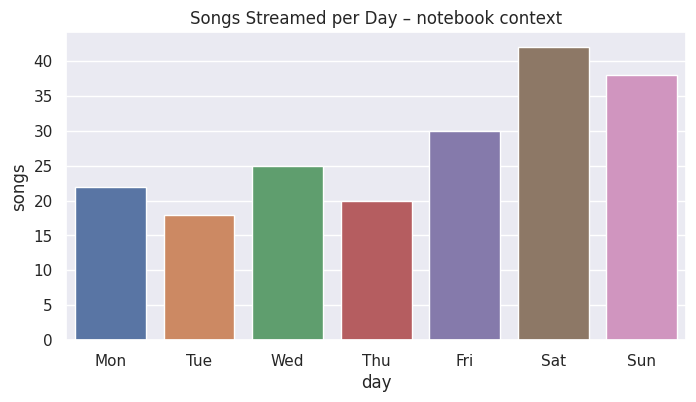

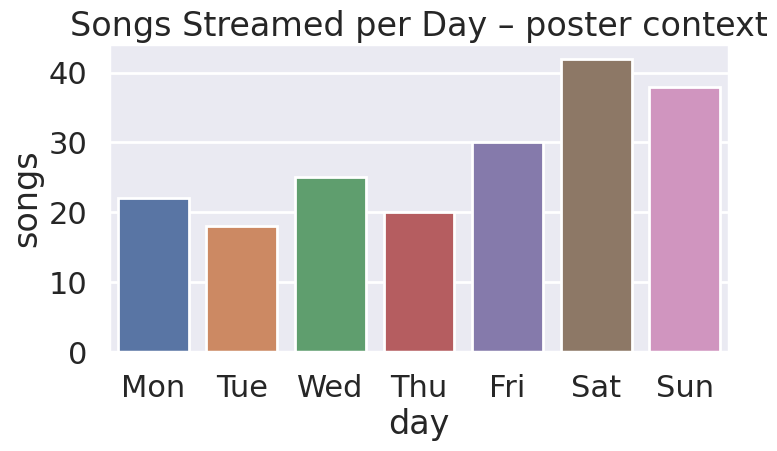

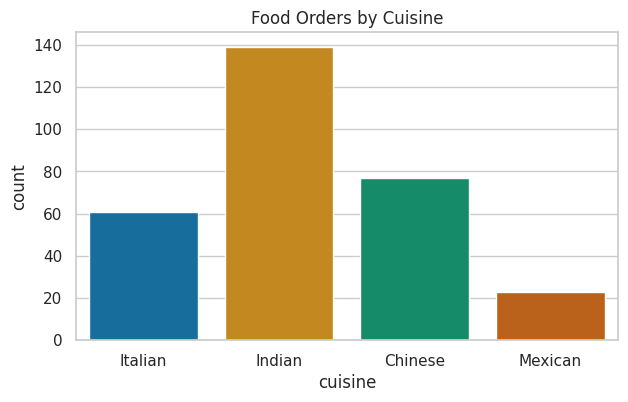

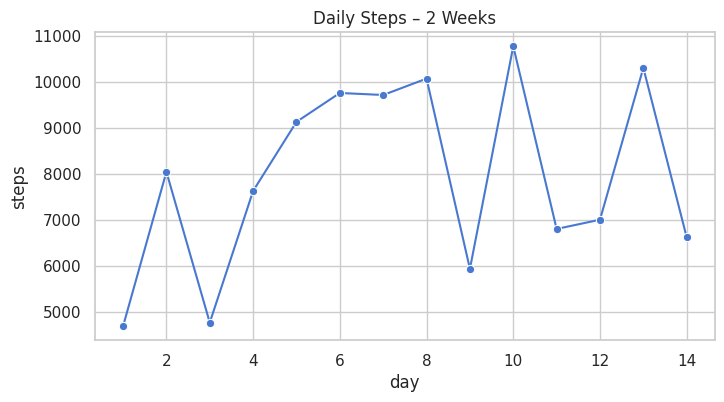

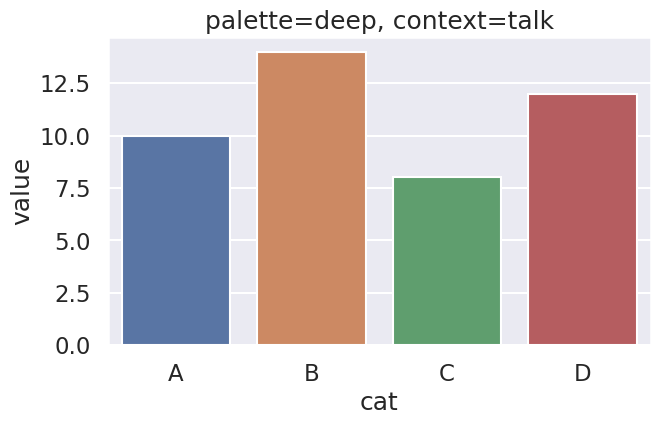

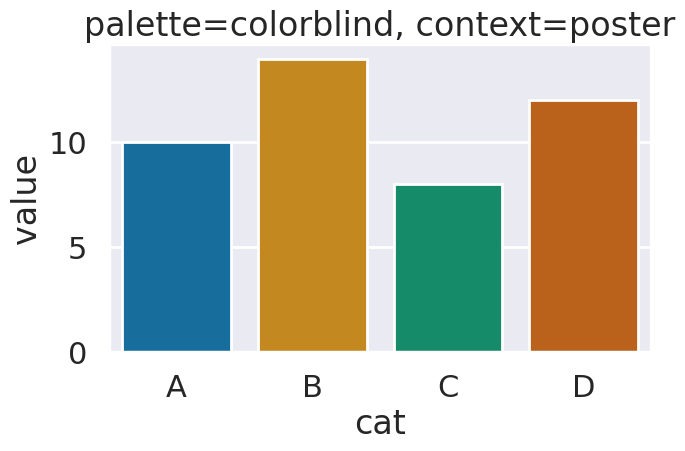

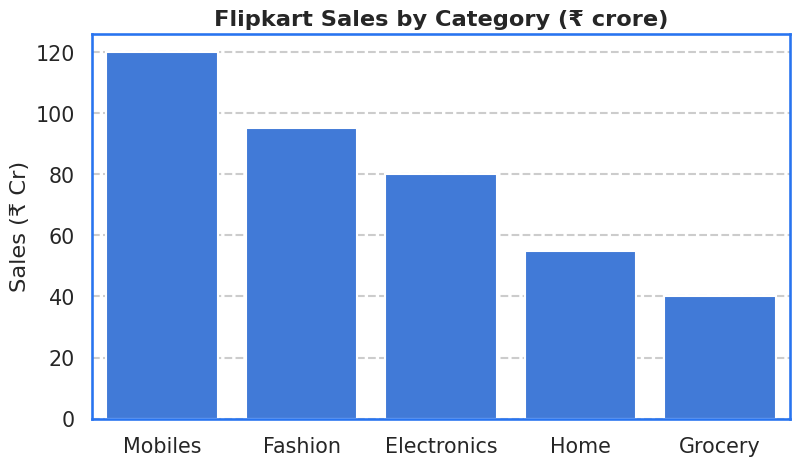

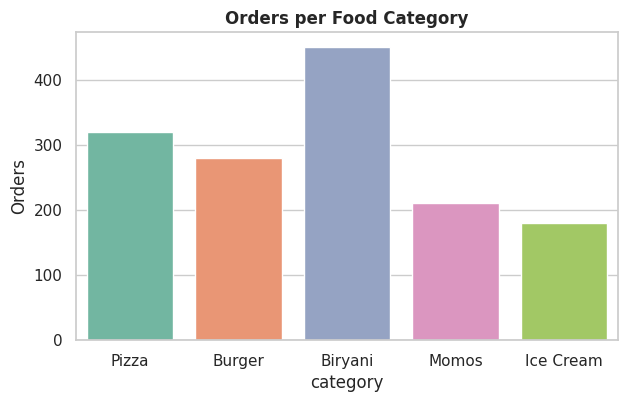

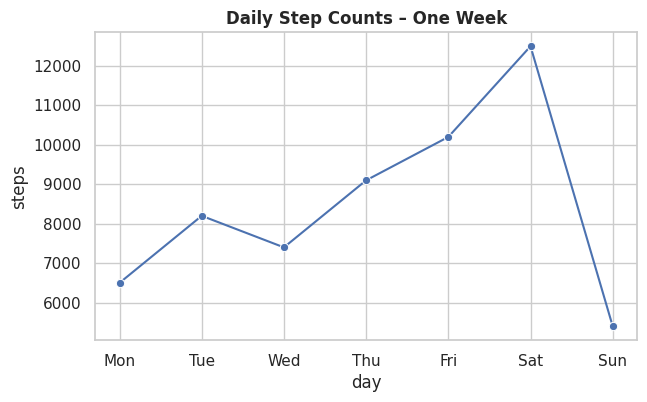

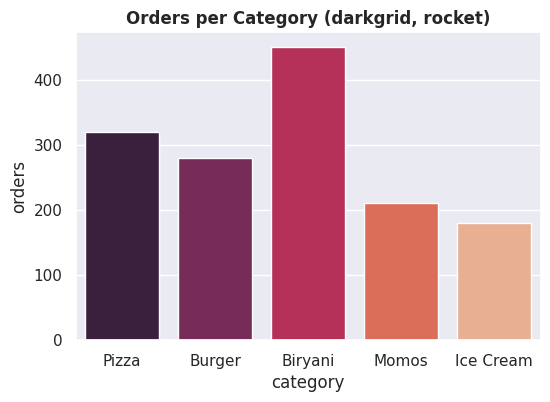

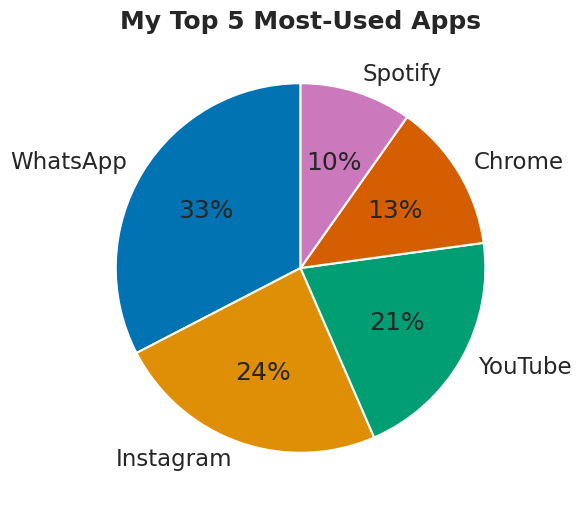

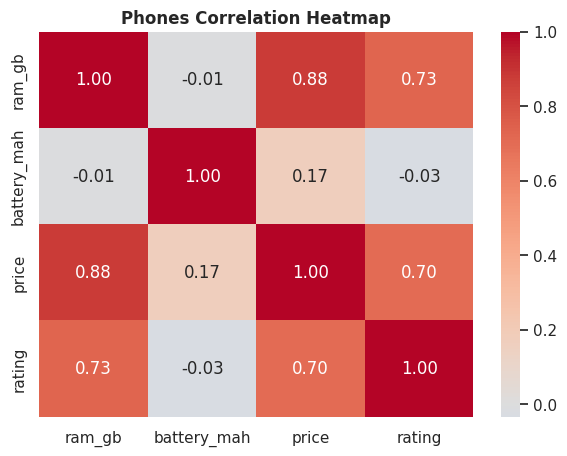

Using SIMULATED dataset (place bank-full.csv beside this notebook to use the real one)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,45,blue-collar,married,primary,no,1497,no,no,cellular,23,feb,275,2,90,2,unknown,yes
1,33,blue-collar,married,secondary,no,4885,no,no,unknown,27,feb,169,4,200,3,unknown,no
2,39,services,single,secondary,no,-4571,no,no,cellular,2,mar,128,1,90,2,unknown,no
3,46,admin.,single,secondary,no,2211,no,yes,telephone,18,dec,43,2,-1,2,unknown,no
4,38,admin.,single,secondary,yes,-1999,no,no,cellular,24,jan,219,5,-1,0,unknown,no
5,35,services,married,tertiary,no,5230,no,no,unknown,3,dec,110,7,-1,3,unknown,no
6,33,retired,divorced,secondary,no,3587,no,no,cellular,27,aug,528,5,-1,2,unknown,no
7,44,self-employed,divorced,tertiary,no,3498,yes,no,cellular,4,may,227,6,-1,2,unknown,no
8,37,unemployed,married,secondary,no,-1089,no,no,cellular,4,apr,84,4,300,2,unknown,no
9,36,management,married,secondary,no,2038,yes,no,cellular,9,dec,31,2,-1,2,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        5000 non-null   int64 
 1   job        5000 non-null   object
 2   marital    5000 non-null   object
 3   education  5000 non-null   object
 4   default    5000 non-null   object
 5   balance    5000 non-null   int64 
 6   housing    5000 non-null   object
 7   loan       5000 non-null   object
 8   contact    5000 non-null   object
 9   day        5000 non-null   int64 
 10  month      5000 non-null   object
 11  duration   5000 non-null   int64 
 12  campaign   5000 non-null   int64 
 13  pdays      5000 non-null   int64 
 14  previous   5000 non-null   int64 
 15  poutcome   5000 non-null   object
 16  y          5000 non-null   object
dtypes: int64(7), object(10)
memory usage: 664.2+ KB


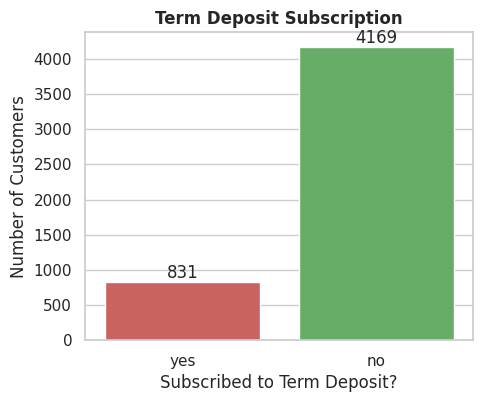

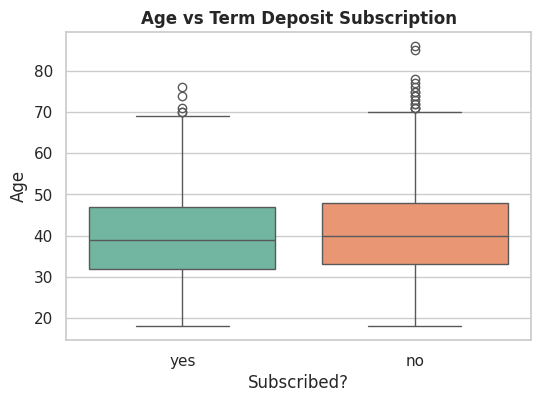

      count  mean   std   min   25%   50%   75%   max
y                                                    
no   4169.0  40.5  10.9  18.0  33.0  40.0  48.0  86.0
yes   831.0  39.9  11.0  18.0  32.0  39.0  47.0  76.0


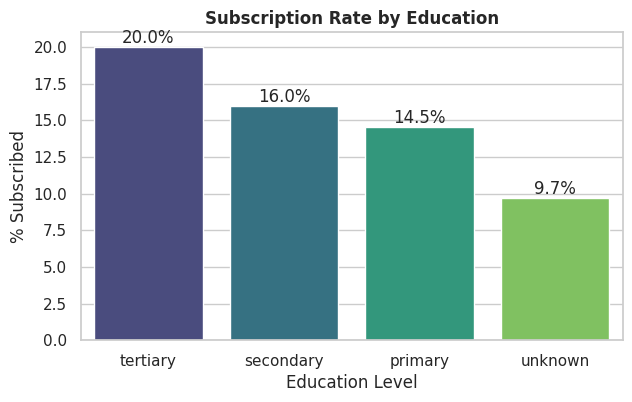

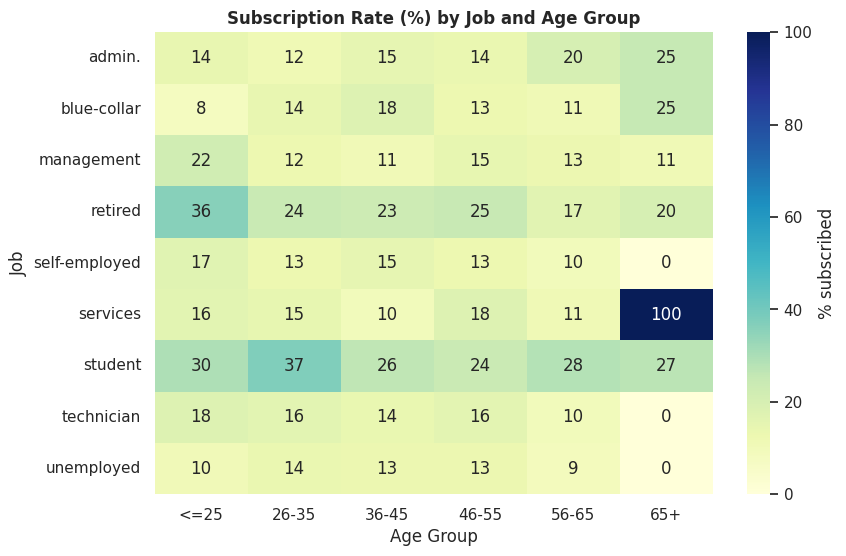

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== Seaborn Assignment (Sessions 1-11 + Case Study 1) - paste into ONE Google Colab cell =====
!pip install -q seaborn statsmodels
from IPython.display import display


# ========== SESSION 1 – Introduction to Seaborn & Themes ==========

# ========== Task 1 – Install, import, versions ==========
# Run once in a terminal / notebook cell if not installed:
# !pip install seaborn matplotlib pandas numpy statsmodels

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import warnings
warnings.filterwarnings("ignore")

os.makedirs("outputs", exist_ok=True)
rng = np.random.default_rng(42)

print("Seaborn version   :", sns.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)


# ========== Task 2 – `sns.lineplot()` weekly temperature ==========
days  = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
temps = [32, 34, 33, 35, 36, 37, 34]

sns.set_theme(style="darkgrid")
plt.figure(figsize=(7, 4))
sns.lineplot(x=days, y=temps, marker="o")
plt.xlabel("Day of the Week")
plt.ylabel("Temperature (°C)")
plt.title("Weekly Temperature Trend")
plt.show()


# ========== Task 3 – Axes-level (`lineplot`) vs figure-level (`relplot`) ==========
# Axes-level: draws on a single matplotlib Axes that YOU create/control
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(x=days, y=temps, marker="o", ax=ax)
ax.set(xlabel="Day of the Week", ylabel="Temperature (°C)", title="Weekly Temperature Trend (axes-level)")
plt.show()

# Figure-level: creates its OWN figure (a FacetGrid) – you control size with height/aspect
g = sns.relplot(x=days, y=temps, kind="line", marker="o", height=4, aspect=1.75)
g.set_axis_labels("Day of the Week", "Temperature (°C)")
g.figure.suptitle("Weekly Temperature Trend (figure-level)", y=1.03)
plt.show()


# ========== Task 4 – Three themes, saved as three images ==========
for style in ["darkgrid", "whitegrid", "ticks"]:
    sns.set_theme(style=style)
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.lineplot(x=days, y=temps, marker="o", ax=ax)
    ax.set(xlabel="Day of the Week", ylabel="Temperature (°C)", title=f"Weekly Temperature Trend – {style}")
    if style == "ticks":
        sns.despine()
    fig.savefig(f"outputs/temp_{style}.png", dpi=150, bbox_inches="tight")
    plt.show()


# ========== SESSION 2 – Categorical Visuals (Countplot, Barplot) ==========
sns.set_theme(style="whitegrid")


# ========== Task 1 – `countplot`: orders per payment method (Swiggy-style) ==========
swiggy = pd.DataFrame({
    "order_id": range(1, 201),
    "payment_method": rng.choice(["UPI", "Card", "Cash", "Wallet"], 200, p=[0.5, 0.25, 0.15, 0.10]),
})
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=swiggy, x="payment_method", order=swiggy.payment_method.value_counts().index, palette="deep", hue="payment_method", legend=False)
ax.bar_label(ax.containers[0]) if ax.containers else None
plt.title("Swiggy Orders by Payment Method"); plt.xlabel("Payment Method"); plt.ylabel("Number of Orders")
plt.show()


# ========== Task 2 – `barplot` mean delivery time per category (Zomato-style) ==========
n = 300
cats = ["Pizza", "Burger", "Biryani", "South Indian"]
zomato = pd.DataFrame({
    "category": rng.choice(cats, n),
    "orders": rng.integers(1, 6, n),
})
base = {"Pizza": 32, "Burger": 28, "Biryani": 40, "South Indian": 25}
zomato["delivery_time"] = zomato.category.map(base) + rng.normal(0, 6, n)

plt.figure(figsize=(7, 4))
sns.barplot(data=zomato, x="category", y="delivery_time", estimator="mean", hue="category", palette="muted", legend=False)
plt.title("Average Delivery Time by Food Category"); plt.xlabel("Food Category"); plt.ylabel("Avg Delivery Time (min)")
plt.show()


# ========== Task 3 – Same plot with `estimator=sum` (total orders) ==========
plt.figure(figsize=(7, 4))
sns.barplot(data=zomato, x="category", y="orders", estimator=sum, errorbar=None, hue="category", palette="muted", legend=False)
plt.title("Total Number of Orders by Food Category"); plt.xlabel("Food Category"); plt.ylabel("Total Orders")
plt.show()


# ========== Task 4 – Movie genres (BookMyShow-style), confidence interval removed ==========
bms = pd.DataFrame({"genre": rng.choice(["Action", "Comedy", "Drama", "Thriller", "Romance", "Horror"], 250, p=[.25,.2,.2,.15,.12,.08])})

# countplot just counts rows, so it has no confidence interval to remove.
plt.figure(figsize=(7, 4))
sns.countplot(data=bms, x="genre", order=bms.genre.value_counts().index, hue="genre", palette="viridis", legend=False)
plt.title("Movie Genres – countplot"); plt.show()

# The 'ci=None' hint belongs to barplot. In seaborn >= 0.12 `ci` is deprecated -> use errorbar=None.
genre_counts = bms.genre.value_counts().reset_index()
genre_counts.columns = ["genre", "count"]
bms["ones"] = 1
plt.figure(figsize=(7, 4))
sns.barplot(data=bms, x="genre", y="ones", estimator=sum, errorbar=None, order=genre_counts.genre, hue="genre", palette="viridis", legend=False)
plt.ylabel("Count"); plt.title("Movie Genres – barplot (errorbar=None, i.e. old ci=None)"); plt.show()


# ========== SESSION 3 – Distribution Plots (Histplot, Kdeplot) ==========

# ========== Task 1 – `histplot` of Swiggy delivery times (≥30 values) ==========
delivery_times = np.round(rng.normal(32, 8, 120).clip(10, 70), 1)
plt.figure(figsize=(7, 4))
sns.histplot(delivery_times, bins=15, color="tab:orange")
plt.title("Distribution of Swiggy Delivery Times"); plt.xlabel("Delivery Time (min)"); plt.show()


# ========== Task 2 – `kdeplot` of daily step counts for one month ==========
steps = rng.normal(8000, 2500, 30).clip(1500, 16000).astype(int)
plt.figure(figsize=(7, 4))
sns.kdeplot(steps, fill=True, color="tab:green")
plt.title("Daily Step Counts (30 days) – Probability Density"); plt.xlabel("Steps per day"); plt.ylabel("Density"); plt.show()


# ========== Task 3 – Histogram + KDE overlay: monthly Zomato spend ==========
spend = np.round(rng.gamma(shape=5, scale=250, size=200)).astype(int)   # rupees
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(spend, bins=20, stat="density", color="skyblue", ax=ax)
sns.kdeplot(spend, color="crimson", linewidth=2, ax=ax)
ax.set(title="Zomato Monthly Spending (₹) – Histogram + KDE", xlabel="Spend (₹)", ylabel="Density"); plt.show()


# ========== Task 4 – IPL scores: effect of number of bins ==========
ipl_scores = np.round(rng.normal(165, 28, 150)).astype(int).clip(80, 260)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, b in zip(axes, [5, 10, 20]):
    sns.histplot(ipl_scores, bins=b, ax=ax, color="tab:purple")
    ax.set_title(f"bins = {b}"); ax.set_xlabel("Runs")
plt.suptitle("IPL Run Distribution", y=1.02); plt.show()


# ========== SESSION 4 – Boxplot & Violin Plot ==========

# ========== Task 1 – Load a CSV of Flipkart prices → `boxplot` ==========
prices = np.concatenate([rng.lognormal(8.0, 0.6, 195), rng.uniform(60000, 90000, 5)])
pd.DataFrame({"product_id": range(1, 201), "price": prices.round(0)}).to_csv("flipkart_prices.csv", index=False)

fk = pd.read_csv("flipkart_prices.csv")
plt.figure(figsize=(7, 3.5))
sns.boxplot(x=fk["price"], color="lightsalmon")
plt.title("Flipkart Product Price Distribution"); plt.xlabel("Price (₹)"); plt.show()


# ========== Task 2 – `violinplot`: Fast Food vs Desserts order amounts ==========
zom = pd.DataFrame({
    "category": ["Fast Food"] * 150 + ["Desserts"] * 150,
    "order_amount": np.concatenate([rng.normal(450, 120, 150), rng.normal(280, 70, 150)]).clip(60),
})
plt.figure(figsize=(6, 4))
sns.violinplot(data=zom, x="category", y="order_amount", hue="category", palette="pastel", legend=False)
plt.title("Order Amounts: Fast Food vs Desserts"); plt.ylabel("Order Amount (₹)"); plt.show()


# ========== Task 3 – IPL ticket prices: boxplot + outliers ==========
tickets = np.array([1500, 1800, 2000, 2200, 2500, 2500, 2800, 3000, 3200, 3500, 3800, 4000, 4500, 5000, 5500, 6000, 12000, 18000, 25000])
plt.figure(figsize=(7, 3.5))
sns.boxplot(x=tickets, color="lightgreen"); sns.stripplot(x=tickets, color="k", size=4)
plt.title("IPL Ticket Prices"); plt.xlabel("Price (₹)"); plt.show()

q1, q3 = np.percentile(tickets, [25, 75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, whisker limits=({lo}, {hi})")
print("Outliers:", tickets[(tickets < lo) | (tickets > hi)])


# ========== Task 4 – Violin plot of daily steps ==========
fit = np.concatenate([rng.normal(4000, 1200, 40), rng.normal(10000, 1800, 50)]).clip(500)
plt.figure(figsize=(5, 5))
sns.violinplot(y=fit, color="skyblue", inner="quartile")
plt.title("Daily Step Counts (Google Fit)"); plt.ylabel("Steps"); plt.show()


# ========== SESSION 5 – Pairplot ==========
tips = sns.load_dataset("tips")
print(tips.head())


# ========== Task 1 – Basic pairplot ==========
sns.pairplot(tips); plt.show()


# ========== Task 2 – `hue='sex'` ==========
sns.pairplot(tips, hue="sex"); plt.show()


# ========== Task 3 – `hue='smoker'`, `diag_kind='kde'` ==========
sns.pairplot(tips, hue="smoker", diag_kind="kde"); plt.show()


# ========== Task 4 – Two columns only, `vars=`, `hue='time'` ==========
sns.pairplot(tips, vars=["total_bill", "tip"], hue="time"); plt.show()


# ========== SESSION 6 – Jointplot ==========

# ========== Task 1 – Flipkart rating vs price (`kind='scatter'`) ==========
n = 300
rating = rng.normal(4.1, 0.4, n).clip(1, 5)
price = (rng.lognormal(9, 0.5, n) * (1 + (rating - 4) * 0.3)).round(0)
pd.DataFrame({"rating": rating.round(1), "price": price}).to_csv("flipkart_ratings.csv", index=False)
fkr = pd.read_csv("flipkart_ratings.csv")
sns.jointplot(data=fkr, x="rating", y="price", kind="scatter"); plt.show()


# ========== Task 2 – Swiggy delivery time vs order value (`kind='hex'`) ==========
n = 500
dt = rng.normal(32, 8, n).clip(10, 70)
ov = (150 + dt * 6 + rng.normal(0, 120, n)).clip(80)
sw = pd.DataFrame({"delivery_time": dt, "order_value": ov})
sns.jointplot(x="delivery_time", y="order_value", data=sw, kind="hex", color="tab:red"); plt.show()


# ========== Task 3 – Instagram likes vs comments (`kind='kde'`) ==========
likes = rng.lognormal(6, 0.7, 300)
insta = pd.DataFrame({"likes": likes, "comments": likes * rng.uniform(0.02, 0.08, 300)})
sns.jointplot(data=insta, x="likes", y="comments", kind="kde", fill=True, cmap="Blues"); plt.show()


# ========== Task 4 – Compare all three on Zomato reviews (rating vs number of reviews) ==========
n = 400
zr_rating = rng.normal(3.9, 0.5, n).clip(1, 5)
zr = pd.DataFrame({"rating": zr_rating, "num_reviews": (rng.lognormal(5, 1, n) * (zr_rating / 4) ** 3).round()})
for k in ["scatter", "hex", "kde"]:
    g = sns.jointplot(data=zr, x="rating", y="num_reviews", kind=k)
    g.figure.suptitle(f"kind = '{k}'", y=1.02); plt.show()


# ========== SESSION 7 – Heatmaps & Correlation ==========

# ========== Task 1 – Food-delivery DataFrame + `.corr()` ==========
n = 20
dist = rng.uniform(1, 12, n)
fd = pd.DataFrame({
    "delivery_distance": dist,
    "delivery_time": 12 + dist * 2.5 + rng.normal(0, 3, n),
    "order_value": rng.uniform(150, 900, n),
})
fd["tip_amount"] = fd.order_value * 0.05 + rng.normal(0, 5, n)
fd["rating"] = (5 - fd.delivery_time * 0.04 + rng.normal(0, 0.3, n)).clip(1, 5)
corr = fd.corr()
corr.round(2)


# ========== Task 2 – Annotated heatmap ==========
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f")
plt.title("Correlation – Food Delivery Orders"); plt.show()


# ========== Task 3 – Diverging palette (`coolwarm`) + strongest negative correlation ==========
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=.5)
plt.title("Correlation – coolwarm"); plt.show()

# strongest negative pair
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values()
print("Strongest negative correlation:", pairs.index[0], "=", round(pairs.iloc[0], 2))


# ========== Task 4 – Flipkart mobile phones: ≥4 numeric columns ==========
n = 150
ram = rng.choice([3, 4, 6, 8, 12], n)
battery = rng.choice([3500, 4000, 5000, 6000], n)
phones = pd.DataFrame({
    "ram_gb": ram,
    "battery_mah": battery,
    "price": (ram * 2200 + battery * 1.2 + rng.normal(0, 3000, n) + 4000).round(),
})
phones["rating"] = (3.2 + ram * 0.06 + phones.price / 80000 + rng.normal(0, 0.25, n)).clip(1, 5).round(1)
plt.figure(figsize=(7, 5))
sns.heatmap(phones.corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1)
plt.title("Flipkart Mobile Phones – Correlation Heatmap"); plt.show()


# ========== SESSION 8 – Relational Plots ==========

# ========== Task 1 – `scatterplot`: followers vs posts (20 users) ==========
insta_users = pd.DataFrame({"followers": rng.integers(200, 50000, 20)})
insta_users["posts"] = (insta_users.followers / 400 + rng.normal(20, 15, 20)).clip(3).round()
plt.figure(figsize=(6, 4))
sns.scatterplot(data=insta_users, x="followers", y="posts", s=80)
plt.xlabel("Number of Followers"); plt.ylabel("Number of Posts"); plt.title("Followers vs Posts (20 Instagram users)"); plt.show()


# ========== Task 2 – `lineplot`: daily Zomato orders over a month ==========
daily = pd.DataFrame({"day": range(1, 31), "orders": rng.integers(120, 300, 30)})
plt.figure(figsize=(9, 4))
sns.lineplot(data=daily, x="day", y="orders", marker="o")
plt.title("Daily Zomato Orders – One Month"); plt.xlabel("Day of Month"); plt.ylabel("Orders"); plt.show()


# ========== Task 3 – `relplot` with `hue='genre'` ==========
movies = pd.DataFrame({
    "movie": [f"Movie {i}" for i in range(1, 16)],
    "rating": [7.8, 6.5, 8.2, 7.1, 6.9, 8.5, 7.4, 6.2, 7.9, 8.0, 6.8, 7.2, 8.4, 7.0, 6.6],
    "reviews": [12000, 8500, 15000, 9000, 7000, 18000, 11000, 5000, 13000, 14000, 6500, 9500, 16000, 8000, 7500],
    "genre": ["Action"]*5 + ["Comedy"]*5 + ["Drama"]*5,
})
sns.relplot(data=movies, x="rating", y="reviews", hue="genre", style="genre", s=120, height=4.5, aspect=1.3)
plt.title("Movie Ratings vs Reviews by Genre"); plt.show()


# ========== Task 4 – `regplot`: YouTube hours vs exam score (25 students) ==========
yt = pd.DataFrame({"hours": rng.uniform(0, 8, 25)})
yt["score"] = (92 - yt.hours * 5.5 + rng.normal(0, 6, 25)).clip(20, 100)
plt.figure(figsize=(6, 4))
sns.regplot(data=yt, x="hours", y="score")
plt.xlabel("Hours on YouTube / day"); plt.ylabel("Exam Score"); plt.title("YouTube Hours vs Exam Score"); plt.show()
print("Correlation r =", round(yt.hours.corr(yt.score), 2))


# ========== SESSION 9 – Regression Plots ==========

# ========== Task 1 – `regplot`: likes vs comments (12 posts) ==========
ig = pd.DataFrame({"likes": rng.integers(100, 5000, 12)})
ig["comments"] = (ig.likes * 0.05 + rng.normal(0, 25, 12)).clip(1).round()
plt.figure(figsize=(6, 4)); sns.regplot(data=ig, x="likes", y="comments", color="purple")
plt.title("Instagram: Likes vs Comments"); plt.show()


# ========== Task 2 – `lmplot`: order price vs delivery time (20 rows) ==========
zp = pd.DataFrame({"price": rng.uniform(150, 1000, 20)})
zp["delivery_time"] = 20 + zp.price * 0.02 + rng.normal(0, 3, 20)
sns.lmplot(data=zp, x="price", y="delivery_time", height=4, aspect=1.4)
plt.title("Zomato: Order Price vs Delivery Time"); plt.show()


# ========== Task 3 – Lowess smoothing (Spotify playlists) ==========
sp = pd.DataFrame({"songs": rng.integers(5, 120, 80)})
sp["duration_min"] = sp.songs * 3.4 + rng.normal(0, 18, 80) + np.where(sp.songs > 80, -sp.songs * 0.4, 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=sp, x="songs", y="duration_min", ax=axes[0]); axes[0].set_title("Linear fit")
sns.regplot(data=sp, x="songs", y="duration_min", lowess=True, ax=axes[1], line_kws={"color": "red"}); axes[1].set_title("lowess=True")
plt.show()


# ========== Task 4 – Faceted `lmplot` by preparation method ==========
n = 40
prep = np.repeat(["self-study", "coaching"], n // 2)
students = pd.DataFrame({"hours": rng.uniform(0, 8, n), "prep_method": prep})
students["score"] = np.where(prep == "coaching", 88, 82) - students.hours * np.where(prep == "coaching", 2.5, 6) + rng.normal(0, 5, n)
sns.lmplot(data=students, x="hours", y="score", col="prep_method", height=4)
plt.show()


# ========== Task 5 – Restyle an lmplot (aesthetics only) ==========
fkp = pd.DataFrame({"price": rng.uniform(500, 30000, 60)})
fkp["reviews"] = (fkp.price * 0.4 + rng.normal(0, 2500, 60)).clip(5)
g = sns.lmplot(data=fkp, x="price", y="reviews", height=4.5, aspect=1.4,
               scatter_kws={"color": "darkorange", "s": 50}, line_kws={"color": "navy"})   # regression logic unchanged
g.set_axis_labels("Product Price (₹)", "Number of Reviews")
g.figure.suptitle("Flipkart: Price vs Number of Reviews", y=1.03); plt.show()


# ========== SESSION 10 – Advanced Styling ==========

# ========== Task 1 – 'poster' context vs default ==========
spotify = pd.DataFrame({"day": ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], "songs": [22, 18, 25, 20, 30, 42, 38]})
for ctx in ["notebook", "poster"]:
    sns.set(context=ctx)   # sns.set() applies theme settings
    plt.figure(figsize=(8, 4))
    sns.barplot(data=spotify, x="day", y="songs", hue="day", legend=False)
    plt.title(f"Songs Streamed per Day – {ctx} context"); plt.show()
sns.set_theme()


# ========== Task 2 – Countplot, `colorblind` palette ==========
sns.set_theme(style="whitegrid")
cuisine = pd.DataFrame({"cuisine": rng.choice(["Indian", "Chinese", "Italian", "Mexican"], 300, p=[.45,.25,.2,.1])})
plt.figure(figsize=(7, 4))
sns.countplot(data=cuisine, x="cuisine", hue="cuisine", palette="colorblind", legend=False)
plt.title("Food Orders by Cuisine"); plt.show()


# ========== Task 3 – Line plot, 'muted' palette, 'notebook' context ==========
sns.set_theme(context="notebook", palette="muted", style="whitegrid")
steps14 = pd.DataFrame({"day": range(1, 15), "steps": rng.integers(4000, 12000, 14)})
plt.figure(figsize=(8, 4))
sns.lineplot(data=steps14, x="day", y="steps", marker="o")
plt.title("Daily Steps – 2 Weeks"); plt.show()


# ========== Task 4 – Refactor: `deep/talk` → `colorblind/poster` ==========
data = pd.DataFrame({"cat": list("ABCD"), "value": [10, 14, 8, 12]})
for pal, ctx in [("deep", "talk"), ("colorblind", "poster")]:
    sns.set_theme(context=ctx, palette=pal)
    plt.figure(figsize=(7, 4))
    sns.barplot(data=data, x="cat", y="value", hue="cat", legend=False)
    plt.title(f"palette={pal}, context={ctx}"); plt.show()


# ========== Task 5 – Flipkart-style dashboard theme ==========
def flipkart_theme():
    sns.set(palette="deep", context="talk", font_scale=0.9,
            style="whitegrid", rc={"grid.linestyle": "--", "axes.edgecolor": "#2874F0", "axes.titleweight": "bold"})
flipkart_theme()
sales = pd.DataFrame({"category": ["Mobiles", "Fashion", "Electronics", "Home", "Grocery"], "sales_cr": [120, 95, 80, 55, 40]})
plt.figure(figsize=(9, 5))
sns.barplot(data=sales, x="category", y="sales_cr", color="#2874F0")
plt.title("Flipkart Sales by Category (₹ crore)"); plt.ylabel("Sales (₹ Cr)"); plt.xlabel(""); plt.show()
sns.set_theme()


# ========== SESSION 11 – Exporting High-Quality Charts ==========

# ========== Task 1 – Barplot → PNG @ 300 DPI ==========
sns.set_theme(style="whitegrid")
food = pd.DataFrame({"category": ["Pizza", "Burger", "Biryani", "Momos", "Ice Cream"], "orders": [320, 280, 450, 210, 180]})
plt.figure(figsize=(7, 4))
sns.barplot(data=food, x="category", y="orders", hue="category", palette="Set2", legend=False)
plt.title("Orders per Food Category"); plt.ylabel("Orders")
plt.savefig("outputs/orders_per_category_300dpi.png", dpi=300, bbox_inches="tight"); plt.show()


# ========== Task 2 – Line plot → SVG for PowerPoint ==========
wk = pd.DataFrame({"day": days, "steps": [6500, 8200, 7400, 9100, 10200, 12500, 5400]})
plt.figure(figsize=(7, 4))
sns.lineplot(data=wk, x="day", y="steps", marker="o")
plt.title("Daily Step Counts – One Week")
plt.savefig("outputs/weekly_steps.svg", format="svg", bbox_inches="tight"); plt.show()


# ========== Task 3 – 'darkgrid' + custom palette → PNG @ 1200 DPI ==========
sns.set_theme(style="darkgrid", palette="rocket")
plt.figure(figsize=(6, 4))
sns.barplot(data=food, x="category", y="orders", hue="category", palette="rocket", legend=False)
plt.title("Orders per Category (darkgrid, rocket)")
plt.savefig("outputs/darkgrid_1200dpi.png", dpi=1200, bbox_inches="tight"); plt.show()


# ========== Task 4 – `apply_presentation_theme()` + pie chart of top-5 apps ==========
def apply_presentation_theme():
    sns.set_theme(style="whitegrid", context="talk", palette="colorblind",
                  rc={"font.family": "DejaVu Sans", "axes.titleweight": "bold", "figure.dpi": 100})

apply_presentation_theme()
apps = {"WhatsApp": 150, "Instagram": 110, "YouTube": 95, "Chrome": 60, "Spotify": 45}   # minutes/day
plt.figure(figsize=(6, 6))
plt.pie(apps.values(), labels=apps.keys(), autopct="%1.0f%%", colors=sns.color_palette("colorblind", 5), startangle=90)
plt.title("My Top 5 Most-Used Apps")
plt.savefig("outputs/top5_apps_pie.png", dpi=300, bbox_inches="tight"); plt.show()


# ========== Task 5 – Heatmap exported as 1200 DPI SVG ==========
# --- PROMPT (to paste into ChatGPT) ---
# "Give me Python code to export a Seaborn heatmap as a 1200 DPI SVG file,
#  with annotations and a diverging palette."
#
# --- CODE SNIPPET (typical response; I tested and adapted it below) ---
#   sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
#   plt.savefig("heatmap.svg", format="svg", dpi=1200)
#
# Adaptation notes: SVG is a vector format, so dpi has no effect on quality (it only
# matters for any embedded raster parts). I added bbox_inches="tight" and used my own data.

sns.set_theme(style="white")
plt.figure(figsize=(7, 5))
sns.heatmap(phones.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Phones Correlation Heatmap")
plt.savefig("outputs/heatmap_1200dpi.svg", format="svg", dpi=1200, bbox_inches="tight")
plt.show()


# ========== CASE STUDY 1 – Bank Marketing Campaign Analysis ==========

# ========== Task 1 – Load `bank_df`, head(10), info() ==========
sns.set_theme(style="whitegrid", palette="deep")

if os.path.exists("bank-full.csv"):
    bank_df = pd.read_csv("bank-full.csv", sep=";")      # real UCI/Kaggle file
    print("Loaded REAL dataset")
else:
    # Simulated stand-in with identical columns (overall yes-rate ≈ 12%)
    n = 5000
    age = rng.normal(41, 11, n).clip(18, 95).astype(int)
    education = rng.choice(["primary", "secondary", "tertiary", "unknown"], n, p=[.15, .51, .29, .05])
    job = rng.choice(["admin.", "blue-collar", "management", "technician", "services", "retired", "student", "self-employed", "unemployed"], n)
    duration = rng.gamma(2, 130, n).astype(int)
    p = 0.05 + 0.06*(education == "tertiary") + 0.03*(education == "secondary") + 0.12*np.isin(job, ["student", "retired"]) \
        + 0.0005*np.clip(duration - 200, 0, None) + 0.04*(age > 60)
    y = np.where(rng.random(n) < p.clip(0, 0.9), "yes", "no")
    bank_df = pd.DataFrame({
        "age": age, "job": job, "marital": rng.choice(["married", "single", "divorced"], n, p=[.6, .28, .12]),
        "education": education, "default": rng.choice(["no", "yes"], n, p=[.98, .02]),
        "balance": rng.normal(1300, 2800, n).astype(int), "housing": rng.choice(["yes", "no"], n),
        "loan": rng.choice(["yes", "no"], n, p=[.16, .84]), "contact": rng.choice(["cellular", "telephone", "unknown"], n, p=[.65, .06, .29]),
        "day": rng.integers(1, 29, n), "month": rng.choice(["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"], n),
        "duration": duration, "campaign": rng.integers(1, 10, n), "pdays": rng.choice([-1, 90, 200, 300], n, p=[.8, .08, .07, .05]),
        "previous": rng.integers(0, 4, n), "poutcome": rng.choice(["unknown", "failure", "success", "other"], n, p=[.8, .1, .04, .06]),
        "y": y,
    })
    print("Using SIMULATED dataset (place bank-full.csv beside this notebook to use the real one)")

display(bank_df.head(10))
bank_df.info()


# ========== Task 2 – Countplot of subscription (`y`) ==========
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=bank_df, x="y", hue="y", palette=["#d9534f", "#5cb85c"], legend=False)
ax.bar_label(ax.containers[0]); ax.bar_label(ax.containers[1])
plt.xlabel("Subscribed to Term Deposit?"); plt.ylabel("Number of Customers"); plt.title("Term Deposit Subscription"); plt.show()


# ========== Task 3 – Age vs subscription (boxplot) ==========
plt.figure(figsize=(6, 4))
sns.boxplot(data=bank_df, x="y", y="age", hue="y", palette="Set2", legend=False)
plt.xlabel("Subscribed?"); plt.ylabel("Age"); plt.title("Age vs Term Deposit Subscription"); plt.show()
print(bank_df.groupby("y").age.describe().round(1))


# ========== Task 4 – % subscribed by education level ==========
edu_pct = (bank_df.assign(sub=(bank_df.y == "yes")).groupby("education")["sub"].mean().mul(100).reset_index(name="subscription_pct").sort_values("subscription_pct", ascending=False))
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=edu_pct, x="education", y="subscription_pct", hue="education", palette="viridis", legend=False)
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%")
plt.xlabel("Education Level"); plt.ylabel("% Subscribed"); plt.title("Subscription Rate by Education"); plt.show()


# ========== Task 5 – Two extra visualizations for a fintech like Cred (suggested via an AI assistant) + one implemented ==========
# --- AI-assistant prompt ---
# "Suggest two visualizations to help a fintech startup like Cred understand which users are most likely
#  to buy a new savings product, using the Bank Marketing dataset."
#
# --- Suggestions ---
# 1. Heatmap of subscription rate by job x age-group (pinpoints high-value segments).
# 2. Violin/box plot of account balance (and call duration) split by subscription outcome.
#
# Implementing #1:

bank_df["age_group"] = pd.cut(bank_df.age, [17, 25, 35, 45, 55, 65, 100], labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])
pivot = bank_df.assign(sub=(bank_df.y == "yes")).pivot_table(index="job", columns="age_group", values="sub", aggfunc="mean", observed=False) * 100

plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% subscribed"})
plt.title("Subscription Rate (%) by Job and Age Group"); plt.xlabel("Age Group"); plt.ylabel("Job"); plt.show()


# ========== Download all saved charts (Google Colab) ==========
import shutil
shutil.make_archive("saved_charts", "zip", "outputs")
try:
    from google.colab import files
    files.download("saved_charts.zip")       # downloads the zip to your computer
except ImportError:
    print("Not running in Colab - find saved_charts.zip next to this notebook.")